# Introdução aos Métodos de Associação Genética - Dia 01
Autor: Francisco Agenor de Oliveira Neto

In [ ]:
import numpy as np
import pandas as pd

# Colocando uma seed para termos reprodutibilidade
np.random.seed(42)

# Iremos criar o modelo primeiro, com alguns parâmetros
n_samples = 1000
base_glucose = 90.0 # Valor base do nível de glicose no sangue (glicemia)
effect_a = 15.0     # alelo 'a' está positivamente associado a glicemia
effect_B = -12.0    # alelo 'B' está negativamete associado a glicemia

# 1. Simulando os genótipos
# Aqui geramos uma distribuição de contagem de a (0, 1, 2) com frequência alélica de 30%
count_a = np.random.binomial(n=2, p=0.3, size=n_samples)

# Fazemos o mesmo para B, com frequência alélica de 40%
count_B = np.random.binomial(n=2, p=0.4, size=n_samples)

# 2. Simulando os fenótipos
# Equação: Base + (efeito genético) + erro (noise)
noise = np.random.normal(loc=0, scale=8.0, size=n_samples)
glucose_levels = base_glucose + (effect_a * count_a) + (effect_B * count_B) + noise

# 3. Formatando o dataset
snp1_map = {0: 'AA', 1: 'Aa', 2: 'aa'}
snp2_map = {0: 'bb', 1: 'Bb', 2: 'BB'} # 0 'B's = bb, 1 'B' = Bb, 2 'B's = BB

df = pd.DataFrame({
    'Sample_ID': [f'IND_{i:04d}' for i in range(1, n_samples + 1)],
    'SNP1_Genotype': [snp1_map[val] for val in count_a],
    'SNP2_Genotype': [snp2_map[val] for val in count_B],
    'Count_Allele_a': count_a,
    'Count_Allele_B': count_B,
    'Blood_Glucose': np.round(glucose_levels, 2)
})

# Olhando as primeiras linhas
print(df.head())

  Sample_ID SNP1_Genotype SNP2_Genotype  Count_Allele_a  Count_Allele_B  \
0  IND_0001            AA            bb               0               0   
1  IND_0002            aa            Bb               2               1   
2  IND_0003            Aa            BB               1               2   
3  IND_0004            Aa            Bb               1               1   
4  IND_0005            AA            Bb               0               1   

   Blood_Glucose  
0          82.98  
1         101.38  
2          79.19  
3          95.94  
4          85.31  


/tmp/ipykernel_544/763679918.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_544/763679918.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


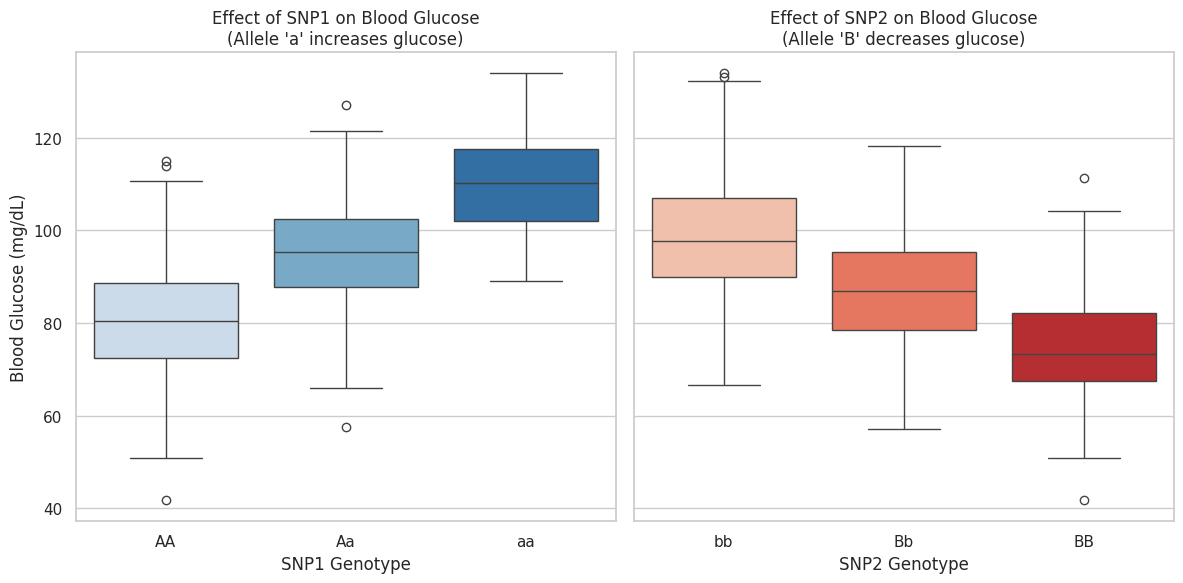

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# Plot 1: Glicemia estatrificado pelo SNP1
sns.boxplot(
    data=df,
    x='SNP1_Genotype',
    y='Blood_Glucose',
    order=['AA', 'Aa', 'aa'],
    ax=axes[0],
    palette="Blues"
)
axes[0].set_title("Effect of SNP1 on Blood Glucose\n(Allele 'a' increases glucose)")
axes[0].set_xlabel("SNP1 Genotype")
axes[0].set_ylabel("Blood Glucose (mg/dL)")

# Plot 2: Glicemia estratificada pelo SNP2
sns.boxplot(
    data=df,
    x='SNP2_Genotype',
    y='Blood_Glucose',
    order=['bb', 'Bb', 'BB'],
    ax=axes[1],
    palette="Reds"
)
axes[1].set_title("Effect of SNP2 on Blood Glucose\n(Allele 'B' decreases glucose)")
axes[1].set_xlabel("SNP2 Genotype")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
import statsmodels.formula.api as smf

# Modelo de regressão linear
# Contagem dos alelos (0, 1, or 2) são nossas variáveis independentes
model = smf.ols("Blood_Glucose ~ Count_Allele_a + Count_Allele_B", data=df)
results = model.fit()

# Printar o resumo do modelo
print(results.summary())

# Printar os coeficiente calculados
print("\n--- Estimated Effects ---")
print(f"Baseline (Intercept): {results.params['Intercept']:.2f} mg/dL (Expected: ~90.0)")
print(f"Effect of allele 'a':  {results.params['Count_Allele_a']:.2f} mg/dL per allele (Expected: ~15.0)")
print(f"Effect of allele 'B': {results.params['Count_Allele_B']:.2f} mg/dL per allele (Expected: ~-12.0)")

                            OLS Regression Results                            
Dep. Variable:          Blood_Glucose   R-squared:                       0.721
Model:                            OLS   Adj. R-squared:                  0.721
Method:                 Least Squares   F-statistic:                     1289.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          3.42e-277
Time:                        18:34:11   Log-Likelihood:                -3475.4
No. Observations:                1000   AIC:                             6957.
Df Residuals:                     997   BIC:                             6971.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         90.1671      0.447    201.

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Criando um modelo primeiro, agora para um fenótipo binários (Alzheimer)
n_samples = 1000
intercept = -2.5      # log-odds base (baixa prevalência)
effect_a = 1.2        # Alelo 'a' aumenta o risco de Alzheimer
effect_B = -0.8       # alelo 'B' é protetivo contra o Alzheimer

# 1. Simulando os genótipos
count_a = np.random.binomial(n=2, p=0.3, size=n_samples)
count_B = np.random.binomial(n=2, p=0.4, size=n_samples)

# 2. Calculando os log-odds
log_odds = intercept + (effect_a * count_a) + (effect_B * count_B)

# Calculando as probabilidades
probabilities = 1 / (1 + np.exp(-log_odds))

# 3. Simulando o fenótipo (0 = Control, 1 = Alzheimer)
# Uma distribuição binomial será gerada a partir das probabilidades calculadas anteriormente
alzheimers_status = np.random.binomial(n=1, p=probabilities, size=n_samples)

# 4. Formatando o dataset
snp1_map = {0: 'AA', 1: 'Aa', 2: 'aa'}
snp2_map = {0: 'bb', 1: 'Bb', 2: 'BB'}

df_binary = pd.DataFrame({
    'Sample_ID': [f'IND_{i:04d}' for i in range(1, n_samples + 1)],
    'SNP1_Genotype': [snp1_map[val] for val in count_a],
    'SNP2_Genotype': [snp2_map[val] for val in count_B],
    'Count_Allele_a': count_a,
    'Count_Allele_B': count_B,
    'Disease_Probability': np.round(probabilities, 3),
    'Alzheimers_Diagnosis': alzheimers_status
})

print(df_binary.head())

  Sample_ID SNP1_Genotype SNP2_Genotype  Count_Allele_a  Count_Allele_B  \
0  IND_0001            AA            bb               0               0   
1  IND_0002            aa            Bb               2               1   
2  IND_0003            Aa            BB               1               2   
3  IND_0004            Aa            Bb               1               1   
4  IND_0005            AA            Bb               0               1   

   Disease_Probability  Alzheimers_Diagnosis  
0                0.076                     0  
1                0.289                     0  
2                0.052                     0  
3                0.109                     0  
4                0.036                     0  


/tmp/ipykernel_544/2144293030.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_544/2144293030.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


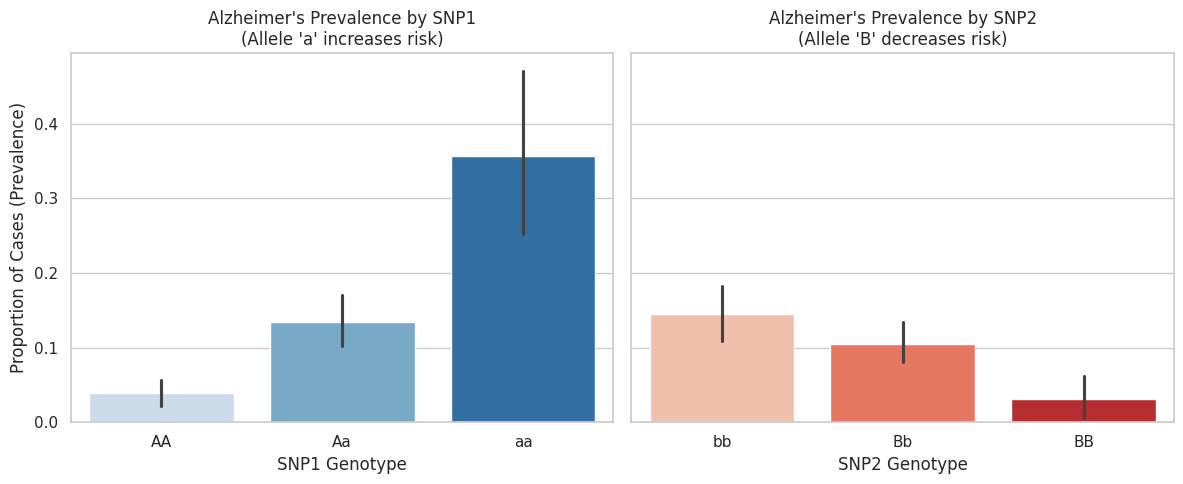

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot 1: Prevalence estratificada pelo SNP1
sns.barplot(
    data=df_binary,
    x='SNP1_Genotype',
    y='Alzheimers_Diagnosis',
    order=['AA', 'Aa', 'aa'],
    ax=axes[0],
    palette="Blues",
    errorbar='ci'
)
axes[0].set_title("Alzheimer's Prevalence by SNP1\n(Allele 'a' increases risk)")
axes[0].set_xlabel("SNP1 Genotype")
axes[0].set_ylabel("Proportion of Cases (Prevalence)")

# Plot 2: Prevalence estratificada pelo  SNP2
sns.barplot(
    data=df_binary,
    x='SNP2_Genotype',
    y='Alzheimers_Diagnosis',
    order=['bb', 'Bb', 'BB'],
    ax=axes[1],
    palette="Reds",
    errorbar='ci'
)
axes[1].set_title("Alzheimer's Prevalence by SNP2\n(Allele 'B' decreases risk)")
axes[1].set_xlabel("SNP2 Genotype")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
import statsmodels.formula.api as smf
import numpy as np

# Modelo de regressão logistica
model = smf.logit("Alzheimers_Diagnosis ~ Count_Allele_a + Count_Allele_B", data=df_binary)
results = model.fit()

# Printando o resumo estatístico
print(results.summary())

# Extrair os coeficientes e calcular os Odds Ratios
print("\n--- Estimated Effects (Odds Ratios) ---")
odds_ratios = np.exp(results.params)
conf_intervals = np.exp(results.conf_int())
conf_intervals.columns = ['2.5%', '97.5%']

for index in odds_ratios.index:
    print(f"{index}: OR = {odds_ratios[index]:.2f} (95% CI: {conf_intervals.loc[index, '2.5%']:.2f} - {conf_intervals.loc[index, '97.5%']:.2f})")

Optimization terminated successfully.
         Current function value: 0.296139
         Iterations 7
                            Logit Regression Results                            
Dep. Variable:     Alzheimers_Diagnosis   No. Observations:                 1000
Model:                            Logit   Df Residuals:                      997
Method:                             MLE   Df Model:                            2
Date:                  Mon, 02 Nov 2026   Pseudo R-squ.:                  0.1295
Time:                          22:23:46   Log-Likelihood:                -296.14
converged:                         True   LL-Null:                       -340.20
Covariance Type:              nonrobust   LLR p-value:                 7.342e-20
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -2.7446      0.216    -12.702      0.000      -3.168      -2.321
C